# Gene Expression Analysis of Leukemia (GSE9476)

## About the Dataset
- **Name:** Leukemia gene expression dataset (GEO accession GSE9476)
- **Source:** NCBI Gene Expression Omnibus (GEO), downloaded from Kaggle: https://www.kaggle.com/datasets/brunogrisci/leukemia-gene-expression-cumida
- **File used:** Leukemia.csv
- **Size:** 64 samples x 22,283 gene probes (Affymetrix microarray)
- **Sample types:** AML (26), Bone_Marrow (10), PB (10), PBSC_CD34 (10), Bone_Marrow_CD34 (8)
- **Values:** log-scale gene expression levels

## Objective
Identify gene expression differences between AML and normal blood and bone marrow cells, explore sample structure using PCA and clustering, and test whether sample type can be predicted from gene expression.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

## 1. Loading the Data

In [ ]:
from google.colab import files
uploaded = files.upload()

df = pd.read_csv("Leukemia.csv")
df

Saving Leukemia.csv to Leukemia.csv


,samples,type,1007_s_at,1053_at,117_at,121_at,1255_g_at,1294_at,1316_at,1320_at,...,AFFX-r2-Hs28SrRNA-5_at,AFFX-r2-Hs28SrRNA-M_at,AFFX-r2-P1-cre-3_at,AFFX-r2-P1-cre-5_at,AFFX-ThrX-3_at,AFFX-ThrX-5_at,AFFX-ThrX-M_at,AFFX-TrpnX-3_at,AFFX-TrpnX-5_at,AFFX-TrpnX-M_at
0,1,Bone_Marrow_CD34,7.745245,7.811210,6.477916,8.841506,4.546941,7.957714,5.344999,4.673364,...,5.058849,6.810004,12.800060,12.718612,5.391512,4.666166,3.974759,3.656693,4.160622,4.139249
1,12,Bone_Marrow_CD34,8.087252,7.240673,8.584648,8.983571,4.548934,8.011652,5.579647,4.828184,...,4.436153,6.751471,12.472706,12.333593,5.379738,4.656786,4.188348,3.792535,4.204414,4.122700
2,13,Bone_Marrow_CD34,7.792056,7.549368,11.053504,8.909703,4.549328,8.237099,5.406489,4.615572,...,4.392061,6.086295,12.637384,12.499038,5.316604,4.600566,3.845561,3.635715,4.174199,4.067152
3,14,Bone_Marrow_CD34,7.767265,7.094460,11.816433,8.994654,4.697018,8.283412,5.582195,4.903684,...,4.633334,6.375991,12.903630,12.871454,5.179951,4.641952,3.991634,3.704587,4.149938,3.910150
4,15,Bone_Marrow_CD34,8.010117,7.405281,6.656049,9.050682,4.514986,8.377046,5.493713,4.860754,...,5.305192,6.700453,12.949352,12.782515,5.341689,4.560315,3.887020,3.629853,4.127513,4.004316
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,60,PBSC_CD34,7.686106,6.856961,6.822222,8.849700,4.440703,8.456949,5.408897,4.708615,...,4.969400,7.016576,12.997293,12.828832,5.084120,4.531087,3.884230,3.619301,4.108490,4.070028
60,61,PBSC_CD34,7.816168,6.875124,6.532324,8.827857,4.515457,8.450286,5.482797,4.667874,...,4.826255,6.577223,12.990305,12.855352,5.260451,4.568651,3.927693,3.634879,4.112277,4.064780
61,62,PBSC_CD34,7.863092,6.896242,6.630690,8.775139,4.458048,8.664517,5.577298,4.853996,...,5.065816,6.583261,12.786121,12.588852,5.451940,4.739944,4.010427,3.668713,4.162220,4.102264
62,63,PBSC_CD34,7.900992,6.787515,6.642927,8.856187,4.499548,9.188459,5.471110,4.637444,...,4.985061,6.815527,13.020089,12.824868,5.459571,4.602105,4.019624,3.570563,4.141371,4.102641


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Columns: 22285 entries, samples to AFFX-TrpnX-M_at
dtypes: float64(22283), int64(1), object(1)
memory usage: 10.9+ MB


## 2. Descriptive Statistics

In [ ]:
mv = df['1007_s_at'].mean()
(mv)

np.float64(7.819371224281932)

In [ ]:
mv = df['1007_s_at'].median()
(mv)

7.81481118605114

In [ ]:
mv = df['1007_s_at'].std()
(mv)

0.1698304265461092

## 3. Correlation Analysis
Computed on the top 20 most variable genes, since the full matrix (22k x 22k) is computationally impractical.

In [ ]:
top = df.drop(columns=['samples', 'type']).var().nlargest(20).index
df[top].corr(numeric_only=True)

,204620_s_at,221731_x_at,215646_s_at,204959_at,214414_x_at,211571_s_at,209116_x_at,205237_at,202833_s_at,204006_s_at,217414_x_at,203535_at,211699_x_at,211745_x_at,209458_x_at,201743_at,211429_s_at,201909_at,214039_s_at,204018_x_at
204620_s_at,1.000000,0.996081,0.989436,0.867873,0.235345,0.983880,0.217501,0.915880,0.899311,0.702550,0.272524,0.908686,0.288146,0.264868,0.271900,0.914257,0.892132,-0.085381,-0.697858,0.275045
221731_x_at,0.996081,1.000000,0.983490,0.861225,0.239806,0.978309,0.222770,0.907584,0.888891,0.692663,0.276541,0.897570,0.292330,0.269554,0.277127,0.902960,0.882796,-0.100310,-0.693503,0.279834
215646_s_at,0.989436,0.983490,1.000000,0.865233,0.228706,0.996194,0.212361,0.901935,0.898660,0.710762,0.265789,0.891473,0.282042,0.258456,0.265526,0.913957,0.888859,-0.078898,-0.714828,0.269560
204959_at,0.867873,0.861225,0.865233,1.000000,0.339723,0.865344,0.354223,0.833414,0.836584,0.836483,0.355990,0.876020,0.365345,0.358457,0.356268,0.882572,0.828995,-0.107049,-0.723891,0.359537
214414_x_at,0.235345,0.239806,0.228706,0.339723,1.000000,0.225866,0.976255,0.284699,0.201797,0.349501,0.993451,0.262676,0.987102,0.993549,0.991691,0.309853,0.200600,0.166902,-0.132943,0.990369
211571_s_at,0.983880,0.978309,0.996194,0.865344,0.225866,1.000000,0.209376,0.896116,0.899506,0.716513,0.262643,0.889653,0.279316,0.255896,0.262228,0.912801,0.890756,-0.090170,-0.715383,0.267630
209116_x_at,0.217501,0.222770,0.212361,0.354223,0.976255,0.209376,1.000000,0.281695,0.197039,0.374873,0.972120,0.258087,0.967931,0.976973,0.975643,0.316714,0.198651,0.178681,-0.105945,0.971091
205237_at,0.915880,0.907584,0.901935,0.833414,0.284699,0.896116,0.281695,1.000000,0.944391,0.785174,0.319654,0.926881,0.343053,0.319263,0.327312,0.960150,0.946214,-0.083127,-0.715939,0.334602
202833_s_at,0.899311,0.888891,0.898660,0.836584,0.201797,0.899506,0.197039,0.944391,1.000000,0.851106,0.230600,0.897135,0.252919,0.234697,0.241291,0.938989,0.993608,-0.093549,-0.766483,0.245835
204006_s_at,0.702550,0.692663,0.710762,0.836483,0.349501,0.716513,0.374873,0.785174,0.851106,1.000000,0.353436,0.764220,0.364759,0.370347,0.372862,0.818690,0.846525,-0.117698,-0.695041,0.369360


## 4. Visualizing Gene Expression

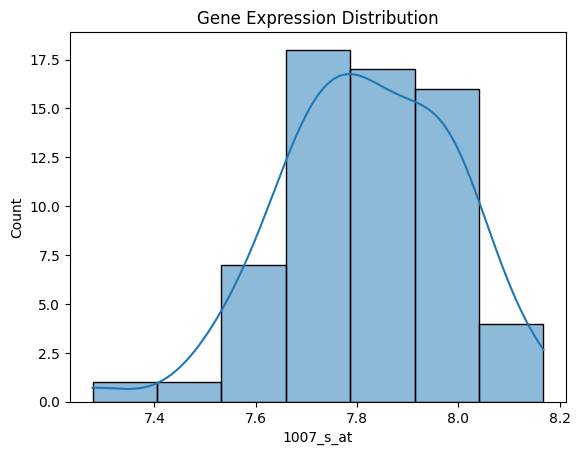

In [ ]:
sns.histplot(x='1007_s_at', data=df, kde=True)
plt.title('Gene Expression Distribution')
plt.show()

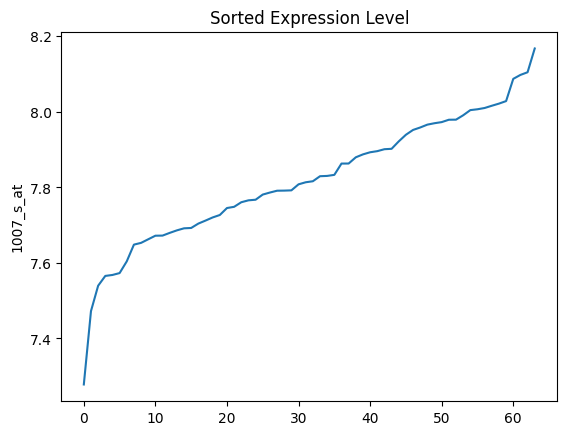

In [ ]:
sorted_expr = df['1007_s_at'].sort_values().reset_index(drop=True)
sns.lineplot(data=sorted_expr)
plt.title("Sorted Expression Level")
plt.show()

## 5. Data Quality Check

In [ ]:
X = df.drop(columns=['samples', 'type'])
y = df['type']

print("Samples x Genes:", X.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Constant genes:", (X.std() == 0).sum())
print("Value range:", round(X.values.min(), 2), "to", round(X.values.max(), 2))
print("Negative values:", int((X.values < 0).sum()))

Samples x Genes: (64, 22283)
Missing values: 0
Duplicate rows: 0
Constant genes: 0
Value range: 3.19 to 14.47
Negative values: 0


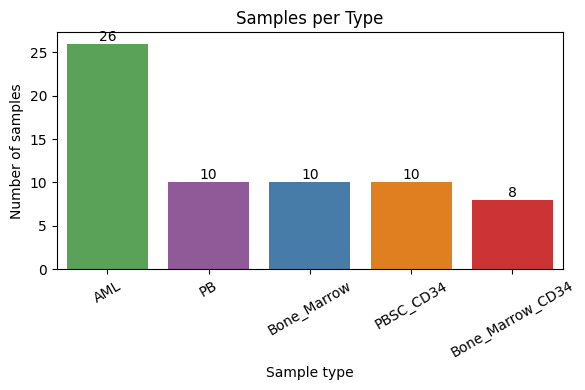

In [ ]:
plt.figure(figsize=(6, 4))
order = y.value_counts().index
ax = sns.countplot(x=y, hue=y, order=order, palette='Set1', legend=False)
for c in ax.containers:
    ax.bar_label(c)
plt.xlabel("Sample type")
plt.ylabel("Number of samples")
plt.title("Samples per Type")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 6. Normalization Check
Boxplots confirm that samples are comparable before analysis.

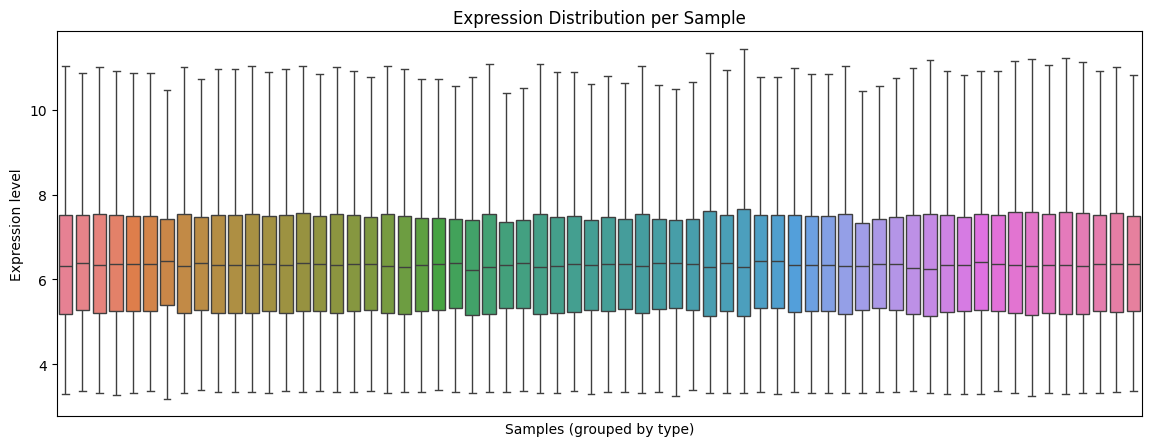

In [ ]:
order = y.sort_values().index
plt.figure(figsize=(14, 5))
sns.boxplot(data=X.loc[order].T, showfliers=False)
plt.xticks([])
plt.xlabel('Samples (grouped by type)')
plt.ylabel('Expression level')
plt.title('Expression Distribution per Sample')
plt.show()

### Outlier Check
Sample-level z-score of average correlation, and the 1.5 x IQR rule for individual values.

In [ ]:
import numpy as np

corr_s = X.T.corr().to_numpy().copy()
np.fill_diagonal(corr_s, np.nan)
avg_corr = pd.Series(np.nanmean(corr_s, axis=1), index=df.index)
z_s = (avg_corr - avg_corr.mean()) / avg_corr.std()
flag = z_s.reindex(z_s.abs().sort_values(ascending=False).index).head(2)
print(pd.DataFrame({'sample': df.loc[flag.index, 'samples'], 'type': df.loc[flag.index, 'type'], 'z': flag.round(2)}))

q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
out_mask = (X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)
print("Outlier values (IQR rule):", round(out_mask.values.mean() * 100, 1), "%")

    sample type     z
47      48   PB -3.19
48      49   PB -3.00
Outlier values (IQR rule): 2.9 %


## 7. Dimensionality Reduction (PCA)
Reducing 22,283 genes to a few principal components to visualize sample structure.

In [ ]:
from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(X)


pca = PCA(n_components=10, random_state=42)
pcs = pca.fit_transform(X_scaled)

pc_df = pd.DataFrame(pcs[:, :3], columns=['PC1', 'PC2', 'PC3'])
pc_df['type'] = y.values
var = pca.explained_variance_ratio_ * 100

print(var.round(1))

[19.5 14.7  6.9  6.2  4.9  3.4  2.9  2.6  2.4  2.1]


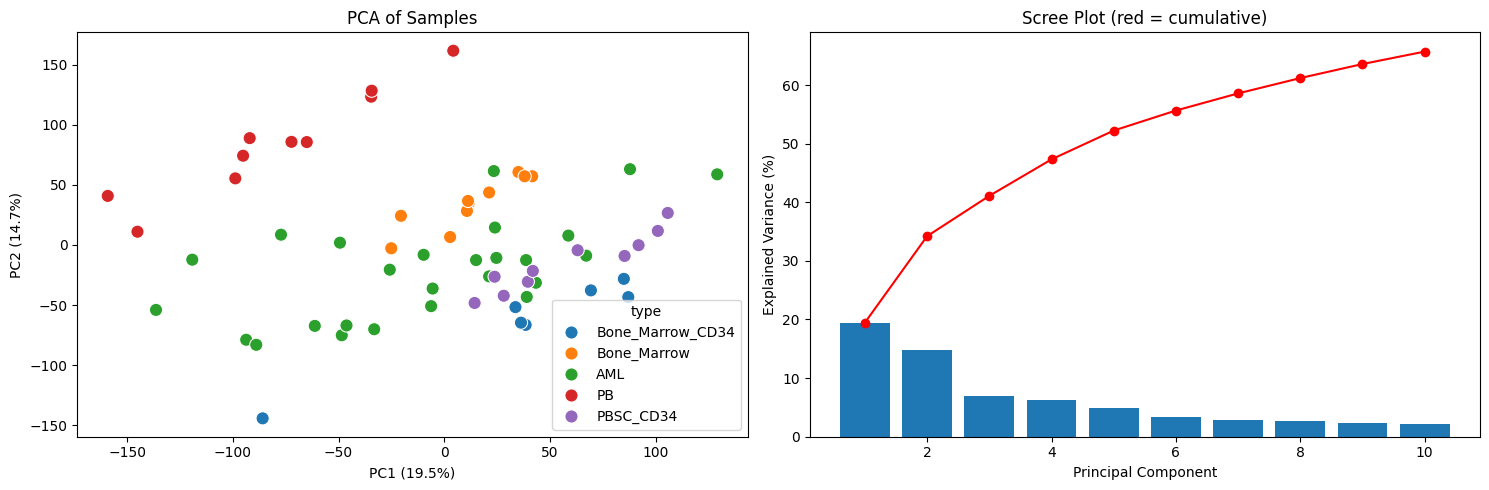

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(data=pc_df, x='PC1', y='PC2', hue='type', s=90, ax=ax[0])
ax[0].set_xlabel(f'PC1 ({var[0]:.1f}%)')
ax[0].set_ylabel(f'PC2 ({var[1]:.1f}%)')
ax[0].set_title('PCA of Samples')

ax[1].bar(range(1, 11), var)
ax[1].plot(range(1, 11), var.cumsum(), color='red', marker='o')
ax[1].set_xlabel('Principal Component')
ax[1].set_ylabel('Explained Variance (%)')
ax[1].set_title('Scree Plot (red = cumulative)')

plt.tight_layout()
plt.show()

## 8. Clustering (KMeans)
Grouping samples without using their labels, then comparing the clusters with the true sample types.

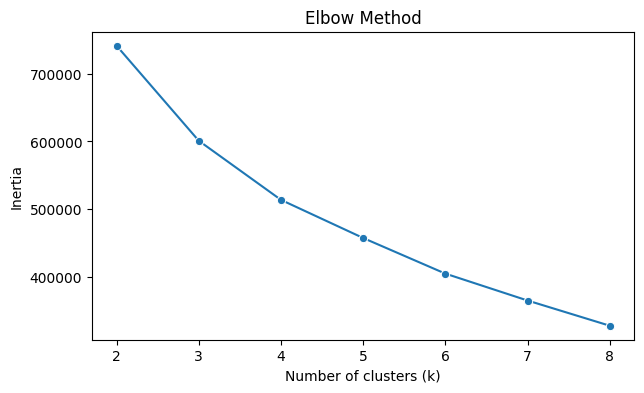

In [ ]:
results = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(pcs)
    results.append((k, km.inertia_))

k_df = pd.DataFrame(results, columns=['k', 'inertia'])

plt.figure(figsize=(7, 4))
sns.lineplot(data=k_df, x='k', y='inertia', marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.show()

ARI: 0.438
cluster            0   1  2   3   4
type                               
AML                0  14  5   4   3
Bone_Marrow        0   0  0   0  10
Bone_Marrow_CD34   0   1  0   7   0
PB                10   0  0   0   0
PBSC_CD34          0   0  0  10   0


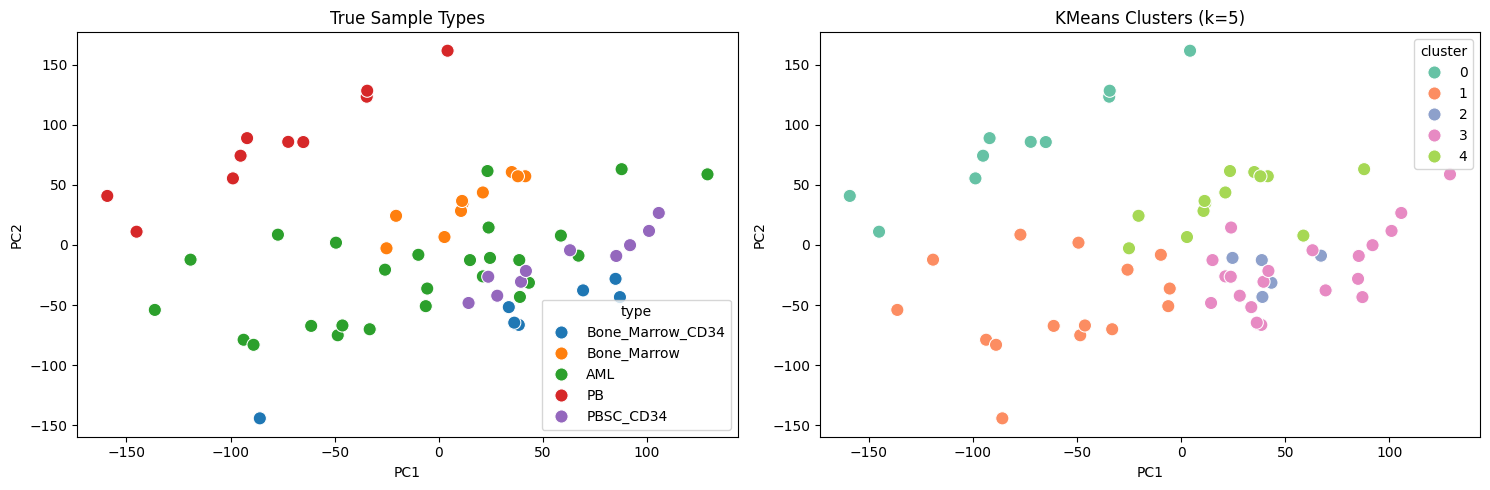

In [ ]:
from sklearn.metrics import adjusted_rand_score

km = KMeans(n_clusters=5, n_init=10, random_state=42)
pc_df['cluster'] = km.fit_predict(pcs)

print("ARI:", round(adjusted_rand_score(y, pc_df['cluster']), 3))
print(pd.crosstab(pc_df['type'], pc_df['cluster']))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=pc_df, x='PC1', y='PC2', hue='type', s=90, ax=ax[0])
ax[0].set_title('True Sample Types')
sns.scatterplot(data=pc_df, x='PC1', y='PC2', hue='cluster', palette='Set2', s=90, ax=ax[1])
ax[1].set_title('KMeans Clusters (k=5)')
plt.tight_layout()
plt.show()

## 9. Similarity Between Sample Types
Average correlation of gene expression between and within sample types.

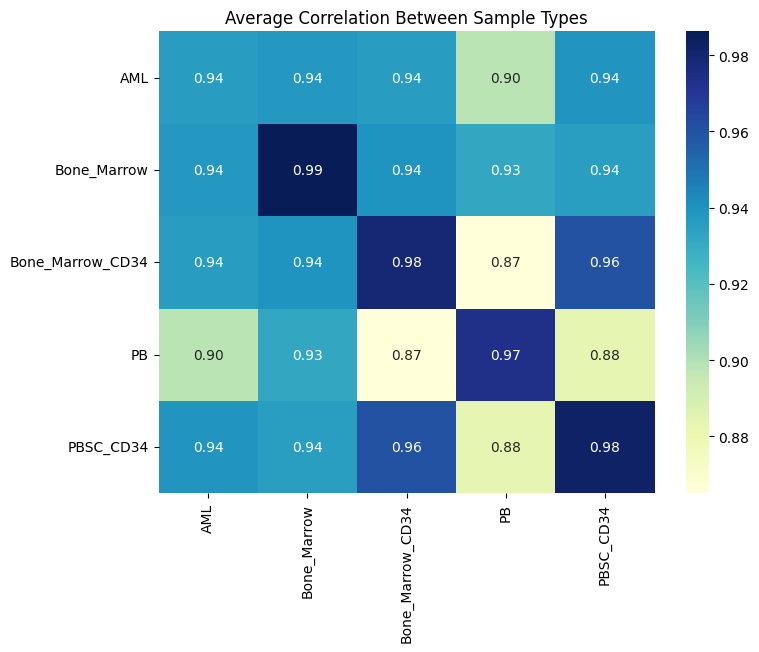

In [ ]:
import numpy as np

corr = X.T.corr().to_numpy().copy()
np.fill_diagonal(corr, np.nan)

types = sorted(y.unique())
labels = y.to_numpy()

sim = pd.DataFrame(index=types, columns=types, dtype=float)
for a in types:
    for b in types:
        sim.loc[a, b] = np.nanmean(corr[np.ix_(labels == a, labels == b)])

plt.figure(figsize=(8, 6))
sns.heatmap(sim, annot=True, fmt='.2f', cmap='YlGnBu')
plt.title('Average Correlation Between Sample Types')
plt.show()

## 10. Differential Expression: AML vs Normal
Welch t-test per gene with Benjamini-Hochberg FDR correction. Significant genes: FDR < 0.05 and |log2 fold change| >= 1.

In [ ]:
from scipy import stats

is_aml = (y == 'AML').values
aml = X[is_aml]
normal = X[~is_aml]

t, p = stats.ttest_ind(aml, normal, equal_var=False)

de = pd.DataFrame({
    'gene': X.columns,
    'log2FC': aml.mean().values - normal.mean().values,
    'pvalue': p
})
de['fdr'] = stats.false_discovery_control(de['pvalue'].values, method='bh')
de['neg_log10_fdr'] = -np.log10(de['fdr'])

de['status'] = 'Not significant'
de.loc[(de['fdr'] < 0.05) & (de['log2FC'] >= 1), 'status'] = 'Up in AML'
de.loc[(de['fdr'] < 0.05) & (de['log2FC'] <= -1), 'status'] = 'Down in AML'

print(de['status'].value_counts())
print("Genes with FDR < 0.05:", (de['fdr'] < 0.05).sum())

status
Not significant    22120
Down in AML          130
Up in AML             33
Name: count, dtype: int64
Genes with FDR < 0.05: 2744


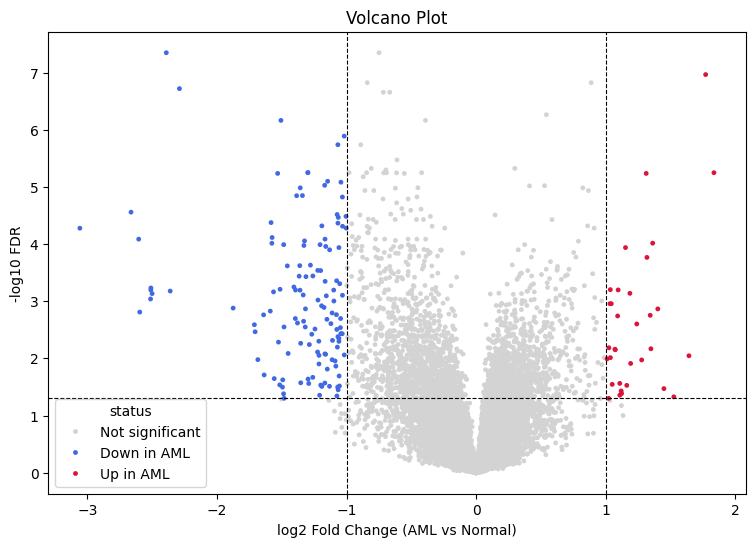

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=de, x='log2FC', y='neg_log10_fdr', hue='status',
    palette={'Not significant': 'lightgrey', 'Up in AML': 'crimson', 'Down in AML': 'royalblue'},
    s=12, linewidth=0
)
plt.axvline(-1, color='black', linestyle='--', linewidth=0.8)
plt.axvline(1, color='black', linestyle='--', linewidth=0.8)
plt.axhline(-np.log10(0.05), color='black', linestyle='--', linewidth=0.8)
plt.xlabel('log2 Fold Change (AML vs Normal)')
plt.ylabel('-log10 FDR')
plt.title('Volcano Plot')
plt.show()

In [ ]:
de[de['status'] != 'Not significant'].sort_values('fdr').head(10)

,gene,log2FC,pvalue,fdr,neg_log10_fdr,status
11609,212224_at,-2.390854,4.045403e-12,4.507186e-08,7.346095,Down in AML
6199,206674_at,1.770205,1.462864e-11,1.086567e-07,6.963944,Up in AML
12622,213241_at,-2.289336,5.148792e-11,1.912176e-07,6.718472,Down in AML
20839,221477_s_at,-1.506437,3.395995e-10,6.879359e-07,6.162452,Down in AML
2940,203414_at,-1.018338,6.977821e-10,1.295723e-06,5.887488,Down in AML
1986,202459_s_at,-1.067216,1.151077e-09,1.832103e-06,5.737050,Down in AML
18074,218711_s_at,-1.298364,4.794466e-09,5.622899e-06,5.250040,Down in AML
889,201362_at,-1.298919,6.344217e-09,5.654728e-06,5.247588,Down in AML
632,201105_at,1.834221,5.831496e-09,5.654728e-06,5.247588,Up in AML
9974,210504_at,-1.531658,7.809954e-09,5.818233e-06,5.235209,Down in AML


## 11. Classification Models
Predicting sample type from gene expression. Feature selection (top 500 genes) is done inside each cross-validation fold to avoid data leakage.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Logistic Regression': Pipeline([
        ('scale', StandardScaler()),
        ('select', SelectKBest(f_classif, k=500)),
        ('clf', LogisticRegression(max_iter=2000))
    ]),
    'Random Forest': Pipeline([
        ('select', SelectKBest(f_classif, k=500)),
        ('clf', RandomForestClassifier(n_estimators=300, random_state=42))
    ])
}

for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy')
    print(name, scores.round(3), "Mean:", round(scores.mean(), 3))

Logistic Regression [1. 1. 1. 1. 1.] Mean: 1.0
Random Forest [1. 1. 1. 1. 1.] Mean: 1.0


                  precision    recall  f1-score   support

             AML       1.00      1.00      1.00        26
     Bone_Marrow       1.00      1.00      1.00        10
Bone_Marrow_CD34       1.00      1.00      1.00         8
              PB       1.00      1.00      1.00        10
       PBSC_CD34       1.00      1.00      1.00        10

        accuracy                           1.00        64
       macro avg       1.00      1.00      1.00        64
    weighted avg       1.00      1.00      1.00        64



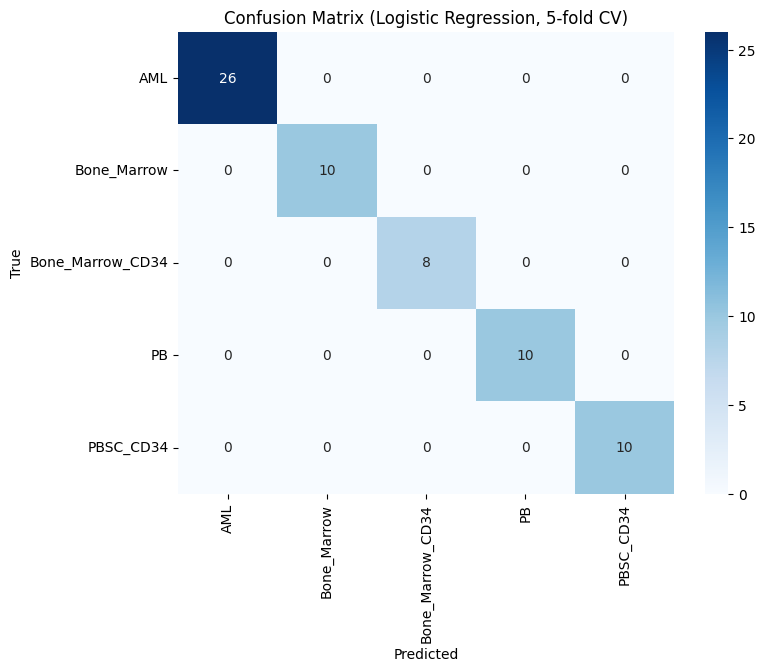

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report

pred = cross_val_predict(models['Logistic Regression'], X, y, cv=cv)
labs = sorted(y.unique())

print(classification_report(y, pred))

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y, pred, labels=labs), annot=True, fmt='d',
            cmap='Blues', xticklabels=labs, yticklabels=labs)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (Logistic Regression, 5-fold CV)')
plt.show()

## Additional Statistics Cited in the Report

In [ ]:
from sklearn.metrics import silhouette_score

med = X.median(axis=1)
print("Sample median range:", round(med.min(), 2), "to", round(med.max(), 2))

c = df[top].corr().to_numpy()
c = c[~np.eye(20, dtype=bool)]
print("Top-20 gene correlations:", round(c.min(), 2), "to", round(c.max(), 2), "| mean absolute:", round(np.abs(c).mean(), 2))

cum = np.cumsum(PCA().fit(X_scaled).explained_variance_ratio_) * 100
print("Components needed for 80% variance:", int(np.argmax(cum >= 80)) + 1)
print("First 10 components:", round(var.sum(), 1), "%")

print("KMeans silhouette (k=5):", round(silhouette_score(pcs, pc_df['cluster']), 2))

sig = de[de['status'] != 'Not significant'].sort_values('log2FC')
print("Strongest decrease:", sig.iloc[0]['gene'], round(sig.iloc[0]['log2FC'], 2))
print("Strongest increase:", sig.iloc[-1]['gene'], round(sig.iloc[-1]['log2FC'], 2))

Sample median range: 6.22 to 6.44
Top-20 gene correlations: -0.77 to 1.0 | mean absolute: 0.54
Components needed for 80% variance: 22
First 10 components: 65.7 %
KMeans silhouette (k=5): 0.26
Strongest decrease: 209116_x_at -3.06
Strongest increase: 201105_at 1.83


## 12. Conclusions

**Data:** 64 samples and 22,283 probes from the GSE9476 leukemia study, covering AML and four normal cell types. The data was clean (no missing values, duplicates, or constant genes) and well normalized across samples. Two peripheral blood (PB) samples were unusual (z = -3.19 and -3.00) and 2.9% of values fell outside the 1.5 x IQR range; all were kept because the differences appear biological.

**Structure:** PCA showed partial separation by type without using any labels, with PB clearly distinct and AML overlapping with several normal types. The first two components explained 34% of the variance, and the first ten explained about 66%.

**Clustering:** KMeans (k=5) fully separated PB and Bone_Marrow samples, and grouped PBSC_CD34 with most Bone_Marrow_CD34 samples. AML samples split across four clusters (ARI around 0.44), suggesting biological heterogeneity within AML. The similarity matrix supports this: AML samples are no more similar to each other (0.94) than to normal cells.

**Differential expression:** 163 probes passed the thresholds (FDR < 0.05, |log2FC| >= 1): 33 higher and 130 lower in AML.

**Classification:** Logistic Regression and Random Forest both reached 100% accuracy in 5-fold stratified cross-validation, with feature selection performed inside each fold to prevent data leakage.

**Limitations:**
- Small sample size (64) from a single study, and no external validation set.
- Perfect accuracy reflects a strong signal in this dataset and may not generalize to other labs or platforms.
- Probe IDs were not mapped to gene names or pathways.
- AML was compared against all normal types pooled together.
- The two unusual PB samples were kept, and the analysis was not repeated without them.

**Future work:** Map probes to gene symbols using the platform annotation, run pathway enrichment analysis, and validate the model on an independent leukemia dataset.